# Decision Tree — When Does Pooling Help or Hurt Survival?

Uses `sklearn.tree.DecisionTreeClassifier` to identify which uncertainty
dimensions predict whether a pooling policy improves or damages `safe_rate`
relative to the strict baseline (both levers = 0).

Runs separately for each of the 3 lever combos:
- **Facility only (1,0)**
- **Ambulance only (0,1)**
- **Both (1,1)**

For each combo, five binary trees are trained:
1. **Helps** — Δ safe_rate > 0
2. **Helps a lot** — Δ safe_rate > threshold
3. **Harms** — Δ safe_rate < 0
4. **Harms a lot** — Δ safe_rate < −threshold
5. **4-class** — harms a lot / harms a bit / helps a bit / helps a lot

In [1]:
import sys
from pathlib import Path
_root = Path(".").resolve()
while not (_root / "paths.py").exists():
    _root = _root.parent
sys.path.insert(0, str(_root))
import paths

In [2]:
FOLDER_NAME = "20260515_201832_scenario_elia_midterm"
LEVER_COLS  = ["facility_eligibility", "ambulance_eligibility"]
OUTCOME     = "safe_rate"
THRESHOLD   = 0.05  # 5 pp boundary between "a bit" and "a lot" 

In [3]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.tree import DecisionTreeClassifier, plot_tree
from sklearn.metrics import classification_report, accuracy_score, ConfusionMatrixDisplay
from sklearn.model_selection import train_test_split

run_folder = paths.MULTI_RUN_OUTPUT / FOLDER_NAME

df = pd.read_csv(run_folder / "results.csv")
print(f"Loaded {len(df)} runs  |  {df['scenario'].nunique()} scenarios  |  "
      f"{df['policy'].nunique()} distinct policies")

Loaded 4000 runs  |  1000 scenarios  |  80 distinct policies


In [4]:
meta_cols      = ["scenario", "policy", "model"]
meta_start     = min(df.columns.get_loc(c) for c in meta_cols if c in df.columns)
input_cols     = df.columns[:meta_start].tolist()
uncertainty_cols = [c for c in input_cols if c not in LEVER_COLS]

feature_cols = [c for c in uncertainty_cols if c != "seed"]

baseline_mask = df[LEVER_COLS].sum(axis=1) == 0

baseline_outcome = (
    df.loc[baseline_mask]
    .groupby("scenario")[OUTCOME]
    .mean()
    .rename("strict")
)

COMBOS = {
    "Facility only (1,0)": {"facility_eligibility": 1, "ambulance_eligibility": 0},
    "Ambulance only (0,1)": {"facility_eligibility": 0, "ambulance_eligibility": 1},
    "Both (1,1)":           {"facility_eligibility": 1, "ambulance_eligibility": 1},
}

CLASS_NAMES_4 = ["Harms a lot", "Harms a bit", "Helps a bit", "Helps a lot"]

def make_4class(delta, threshold):
    labels = np.full(len(delta), 1, dtype=int)
    labels[delta < -threshold] = 0
    labels[(delta >= 0) & (delta < threshold)] = 2
    labels[delta >= threshold] = 3
    return labels

x_base = (
    df.loc[baseline_mask]
    .drop_duplicates(subset="scenario")
    .set_index("scenario")
)

combo_data = {}
for label, lvls in COMBOS.items():
    mask = pd.Series(True, index=df.index)
    for col, val in lvls.items():
        mask &= df[col] == val
    combo_sr = df.loc[mask].groupby("scenario")[OUTCOME].mean().rename("combo")
    comp = pd.concat([baseline_outcome, combo_sr], axis=1).dropna()
    comp["delta"] = comp["combo"] - comp["strict"]

    X = x_base.loc[comp.index, feature_cols].reset_index(drop=True).astype(float)
    y4 = make_4class(comp["delta"].values, THRESHOLD)
    combo_data[label] = {"comp": comp, "X": X, "y4": y4}

    counts = {CLASS_NAMES_4[i]: (y4 == i).sum() for i in range(4)}
    print(f"{label}:  n={len(comp)}  mean \u0394={comp['delta'].mean():.4f}  "
          + "  ".join(f"{k}: {v}" for k, v in counts.items()))

print(f"\nFeatures ({len(feature_cols)}): {feature_cols}")

Facility only (1,0):  n=1000  mean Δ=-0.0136  Harms a lot: 52  Harms a bit: 496  Helps a bit: 452  Helps a lot: 0
Ambulance only (0,1):  n=1000  mean Δ=0.0342  Harms a lot: 27  Harms a bit: 93  Helps a bit: 520  Helps a lot: 360
Both (1,1):  n=1000  mean Δ=0.0241  Harms a lot: 46  Harms a bit: 127  Helps a bit: 567  Helps a lot: 260

Features (14): ['axp_r1_other_bde_min', 'axp_r1_same_bde_min', 'bcas_rate', 'ccp_r1_inter_bn_min', 'ccp_r1_same_bn_min', 'fraction_t1_bcas', 'fraction_t2_bcas', 'n_days', 'r1_r1_inter_bn_min', 'r1_r2_other_bde_min', 'r1_r2_same_bde_min', 'r2_r2_other_bde_min', 'wave_duration_min', 'waves_per_day']


In [5]:
def run_tree(X, y, label, question, class_names, max_depth=4, test_size=0.3):
    unique, counts_arr = np.unique(y, return_counts=True)
    present = [c for c, n in zip(unique, counts_arr) if n >= 3]

    sep = "=" * 70
    print(sep)
    print(f"  {label} — {question}")
    for c, n in zip(unique, counts_arr):
        cname = class_names[c] if isinstance(class_names, (list, dict)) else str(c)
        print(f"    {cname}: {n}")
    print(sep)

    if len(present) < 2:
        print("  Fewer than 2 classes with >=3 samples — skipping.\n")
        return None, None, None

    present_names = [class_names[c] for c in present]
    mask = np.isin(y, present)
    X_f, y_f = X[mask].reset_index(drop=True), y[mask]

    X_train, X_test, y_train, y_test = train_test_split(
        X_f, y_f, test_size=test_size, random_state=42, stratify=y_f,
    )

    tree = DecisionTreeClassifier(
        max_depth=max_depth,
        min_samples_leaf=max(10, int(0.02 * len(y_train))),
        random_state=42,
    )
    tree.fit(X_train, y_train)

    y_pred_test = tree.predict(X_test)
    print(f"  Train acc: {accuracy_score(y_train, tree.predict(X_train)):.3f}  "
          f"Test acc: {accuracy_score(y_test, y_pred_test):.3f}  "
          f"(train={len(X_train)}, test={len(X_test)})")
    print()
    print(classification_report(y_test, y_pred_test,
                                labels=present, target_names=present_names, zero_division=0))

    importances = pd.Series(tree.feature_importances_, index=X_f.columns)
    importances = importances[importances > 0.01].sort_values(ascending=False)
    if not importances.empty:
        print("  Feature importances (>1%):")
        for feat, imp in importances.items():
            print(f"    {feat:30s}  {imp:.3f}")
    print()

    # Confusion matrix only
    fig, ax = plt.subplots(figsize=(5, 4))
    ConfusionMatrixDisplay.from_predictions(
        y_test, y_pred_test, labels=present,
        display_labels=present_names, ax=ax,
        cmap="Blues", colorbar=False,
    )
    ax.set_title(f"{label} — {question}\nConfusion matrix (test set)")
    plt.tight_layout()
    plt.show()

    return tree, X_test, y_test

In [6]:
def display_rules(tree, X_test, y_test, feature_names, class_names, target_class=1, label=""):
    """Extract and display every path leading to target_class with per-rule metrics."""
    if tree is None:
        return

    tree_ = tree.tree_
    if isinstance(class_names, dict):
        idx_to_name = class_names
    else:
        idx_to_name = {i: n for i, n in enumerate(class_names)}

    def fmt_thresh(val):
        """Format threshold with enough precision to avoid ambiguity."""
        if abs(val) < 1:
            return f"{val:.4g}"
        return f"{val:.1f}"

    def recurse(node, path):
        if tree_.children_left[node] == tree_.children_right[node]:
            predicted = tree_.value[node].argmax()
            original_class = tree.classes_[predicted]
            return [(path[:], original_class, tree_.value[node].flatten())]
        feat = feature_names[tree_.feature[node]]
        thresh = tree_.threshold[node]
        t = fmt_thresh(thresh)
        results = []
        results += recurse(tree_.children_left[node],
                           path + [f"{feat} ≤ {t}"])
        results += recurse(tree_.children_right[node],
                           path + [f"{feat} > {t}"])
        return results

    all_paths = recurse(0, [])
    target_paths = [(p, v) for p, cls, v in all_paths if cls == target_class]

    if not target_paths:
        target_n = idx_to_name.get(target_class, target_class)
        print(f"  No paths lead to class {target_n}.\n")
        return

    target_name = idx_to_name.get(target_class, str(target_class))
    sep = "=" * 70
    print(f"\n{sep}")
    print(f"  {label} — Rules predicting: {target_name}")
    print(f"{sep}\n")

    y_pred_all = tree.predict(X_test)
    leaf_ids = tree.apply(X_test)

    def get_leaf_id(path):
        node = 0
        for condition in path:
            if "≤" in condition:
                node = tree_.children_left[node]
            else:
                node = tree_.children_right[node]
        return node

    for i, (path, train_values) in enumerate(target_paths, 1):
        leaf_node = get_leaf_id(path)
        in_leaf = leaf_ids == leaf_node
        n_test = in_leaf.sum()

        if n_test == 0:
            continue

        correct = ((y_pred_all == target_class) & (y_test == target_class) & in_leaf).sum()
        predicted_pos = (y_pred_all[in_leaf] == target_class).sum()
        actual_pos = (y_test[in_leaf] == target_class).sum()
        total_actual_pos = (y_test == target_class).sum()

        precision = correct / predicted_pos if predicted_pos > 0 else 0
        recall = correct / total_actual_pos if total_actual_pos > 0 else 0

        print(f"  Rule {i}:")
        for j, cond in enumerate(path):
            prefix = "  IF  " if j == 0 else "  AND "
            print(f"    {prefix}{cond}")
        print(f"    → {target_name}")
        print(f"    Test: {n_test} samples | precision={precision:.0%} | "
              f"recall={recall:.0%} (covers {correct}/{total_actual_pos} positives)")
        print()

## Facility only (1,0)

In [7]:
cd = combo_data["Facility only (1,0)"]
X, comp = cd["X"], cd["comp"]

  Facility only (1,0) — Does pooling help? (Δ > 0)
    No: 908
    Yes: 92
  Train acc: 0.909  Test acc: 0.907  (train=700, test=300)

              precision    recall  f1-score   support

          No       0.91      1.00      0.95       272
         Yes       0.00      0.00      0.00        28

    accuracy                           0.91       300
   macro avg       0.45      0.50      0.48       300
weighted avg       0.82      0.91      0.86       300

  Feature importances (>1%):
    bcas_rate                       0.442
    r1_r2_other_bde_min             0.226
    axp_r1_other_bde_min            0.127
    ccp_r1_inter_bn_min             0.109
    n_days                          0.058
    fraction_t2_bcas                0.039



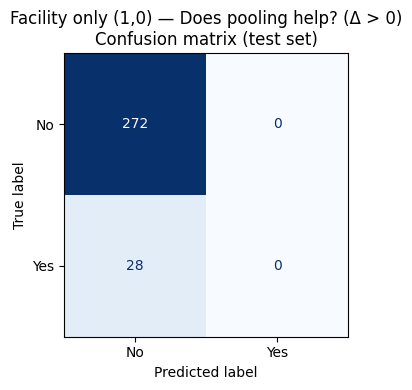

In [8]:
tree_fac_helps, X_test_fac_h, y_test_fac_h = run_tree(
    X, (comp["delta"] > 0).astype(int).values,
    "Facility only (1,0)", "Does pooling help? (\u0394 > 0)",
    class_names={0: "No", 1: "Yes"},
)

In [9]:
display_rules(tree_fac_helps, X_test_fac_h, y_test_fac_h,
              feature_cols, {0: "No", 1: "Yes"}, target_class=1,
              label="Facility only (1,0) — helps")

  No paths lead to class Yes.



In [10]:
tree_fac_lot, X_test_fac_l, y_test_fac_l = run_tree(
    X, (comp["delta"] > THRESHOLD).astype(int).values,
    "Facility only (1,0)", f"Does pooling help a lot? (\u0394 > {THRESHOLD:.0%})",
    class_names={0: "No", 1: "Yes"},
)

  Facility only (1,0) — Does pooling help a lot? (Δ > 5%)
    No: 1000
  Fewer than 2 classes with >=3 samples — skipping.



In [11]:
display_rules(tree_fac_lot, X_test_fac_l, y_test_fac_l,
              feature_cols, {0: "No", 1: "Yes"}, target_class=1,
              label="Facility only (1,0) — helps a lot")

  Facility only (1,0) — Does pooling harm? (Δ < 0)
    No: 452
    Yes: 548
  Train acc: 0.869  Test acc: 0.850  (train=700, test=300)

              precision    recall  f1-score   support

          No       0.92      0.74      0.82       136
         Yes       0.81      0.95      0.87       164

    accuracy                           0.85       300
   macro avg       0.86      0.84      0.84       300
weighted avg       0.86      0.85      0.85       300

  Feature importances (>1%):
    bcas_rate                       0.784
    n_days                          0.105
    fraction_t1_bcas                0.054
    fraction_t2_bcas                0.024
    r1_r2_other_bde_min             0.019
    axp_r1_same_bde_min             0.015



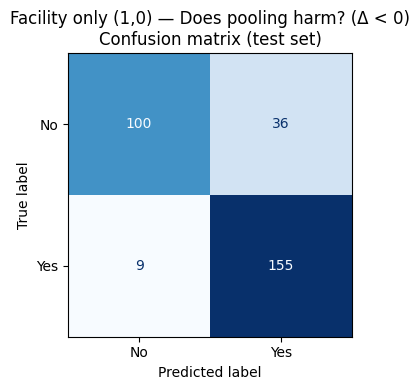

In [12]:
tree_fac_harms, X_test_fac_hr, y_test_fac_hr = run_tree(
    X, (comp["delta"] < 0).astype(int).values,
    "Facility only (1,0)", "Does pooling harm? (\u0394 < 0)",
    class_names={0: "No", 1: "Yes"},
)

In [13]:
display_rules(tree_fac_harms, X_test_fac_hr, y_test_fac_hr,
              feature_cols, {0: "No", 1: "Yes"}, target_class=1,
              label="Facility only (1,0) — harms")


  Facility only (1,0) — harms — Rules predicting: Yes

  Rule 1:
      IF  bcas_rate ≤ 0.0275
      AND bcas_rate > 0.0125
      AND n_days > 1.5
      AND fraction_t1_bcas > 0.05562
    → Yes
    Test: 51 samples | precision=63% | recall=20% (covers 32/164 positives)

  Rule 2:
      IF  bcas_rate > 0.0275
      AND n_days ≤ 1.5
      AND fraction_t2_bcas ≤ 0.2246
      AND r1_r2_other_bde_min > 100.4
    → Yes
    Test: 8 samples | precision=25% | recall=1% (covers 2/164 positives)

  Rule 3:
      IF  bcas_rate > 0.0275
      AND n_days ≤ 1.5
      AND fraction_t2_bcas > 0.2246
      AND axp_r1_same_bde_min ≤ 62.5
    → Yes
    Test: 11 samples | precision=73% | recall=5% (covers 8/164 positives)

  Rule 4:
      IF  bcas_rate > 0.0275
      AND n_days ≤ 1.5
      AND fraction_t2_bcas > 0.2246
      AND axp_r1_same_bde_min > 62.5
    → Yes
    Test: 5 samples | precision=100% | recall=3% (covers 5/164 positives)

  Rule 5:
      IF  bcas_rate > 0.0275
      AND n_days > 1.5
      A

  Facility only (1,0) — Does pooling harm a lot? (Δ < -5%)
    No: 948
    Yes: 52
  Train acc: 0.956  Test acc: 0.923  (train=700, test=300)

              precision    recall  f1-score   support

          No       0.95      0.97      0.96       284
         Yes       0.18      0.12      0.15        16

    accuracy                           0.92       300
   macro avg       0.57      0.55      0.55       300
weighted avg       0.91      0.92      0.92       300

  Feature importances (>1%):
    bcas_rate                       0.377
    r2_r2_other_bde_min             0.317
    r1_r2_same_bde_min              0.172
    ccp_r1_inter_bn_min             0.129



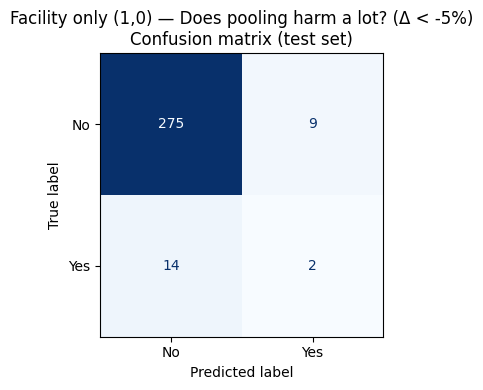

In [14]:
tree_fac_hlot, X_test_fac_hl, y_test_fac_hl = run_tree(
    X, (comp["delta"] < -THRESHOLD).astype(int).values,
    "Facility only (1,0)", f"Does pooling harm a lot? (\u0394 < -{THRESHOLD:.0%})",
    class_names={0: "No", 1: "Yes"},
)

In [15]:
display_rules(tree_fac_hlot, X_test_fac_hl, y_test_fac_hl,
              feature_cols, {0: "No", 1: "Yes"}, target_class=1,
              label="Facility only (1,0) — harms a lot")


  Facility only (1,0) — harms a lot — Rules predicting: Yes

  Rule 1:
      IF  bcas_rate > 0.0425
      AND r1_r2_same_bde_min ≤ 57.2
      AND r2_r2_other_bde_min > 86.3
      AND r2_r2_other_bde_min ≤ 97.4
    → Yes
    Test: 11 samples | precision=18% | recall=12% (covers 2/16 positives)



  Facility only (1,0) — 4-class
    Harms a lot: 52
    Harms a bit: 496
    Helps a bit: 452
  Train acc: 0.819  Test acc: 0.807  (train=700, test=300)

              precision    recall  f1-score   support

 Harms a lot       0.00      0.00      0.00        16
 Harms a bit       0.74      0.94      0.83       149
 Helps a bit       0.92      0.76      0.83       135

    accuracy                           0.81       300
   macro avg       0.55      0.57      0.55       300
weighted avg       0.78      0.81      0.78       300

  Feature importances (>1%):
    bcas_rate                       0.790
    n_days                          0.115
    fraction_t2_bcas                0.052
    ccp_r1_inter_bn_min             0.022
    fraction_t1_bcas                0.011



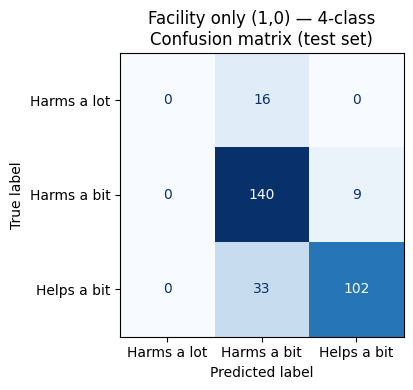

In [16]:
tree_fac_4c, X_test_fac_4, y_test_fac_4 = run_tree(
    cd["X"], cd["y4"],
    "Facility only (1,0)", "4-class",
    class_names=CLASS_NAMES_4,
)

In [17]:
for tc in range(4):
    display_rules(tree_fac_4c, X_test_fac_4, y_test_fac_4,
                  feature_cols, CLASS_NAMES_4, target_class=tc,
                  label="Facility only (1,0) — 4-class")

  No paths lead to class Harms a lot.


  Facility only (1,0) — 4-class — Rules predicting: Harms a bit

  Rule 1:
      IF  bcas_rate ≤ 0.0275
      AND bcas_rate > 0.0125
      AND n_days > 1.5
      AND fraction_t2_bcas > 0.1127
    → Harms a bit
    Test: 40 samples | precision=57% | recall=15% (covers 23/149 positives)

  Rule 2:
      IF  bcas_rate > 0.0275
      AND n_days ≤ 1.5
      AND fraction_t2_bcas > 0.1385
      AND axp_r1_same_bde_min ≤ 62.5
    → Harms a bit
    Test: 16 samples | precision=56% | recall=6% (covers 9/149 positives)

  Rule 3:
      IF  bcas_rate > 0.0275
      AND n_days ≤ 1.5
      AND fraction_t2_bcas > 0.1385
      AND axp_r1_same_bde_min > 62.5
    → Harms a bit
    Test: 11 samples | precision=73% | recall=5% (covers 8/149 positives)

  Rule 4:
      IF  bcas_rate > 0.0275
      AND n_days > 1.5
      AND bcas_rate ≤ 0.0425
      AND ccp_r1_inter_bn_min ≤ 25.2
    → Harms a bit
    Test: 9 samples | precision=56% | recall=3% (covers 5/149 positives

## Ambulance only (0,1)

In [18]:
cd = combo_data["Ambulance only (0,1)"]
X, comp = cd["X"], cd["comp"]

  Ambulance only (0,1) — Does pooling help? (Δ > 0)
    No: 261
    Yes: 739
  Train acc: 0.863  Test acc: 0.783  (train=700, test=300)

              precision    recall  f1-score   support

          No       0.64      0.38      0.48        78
         Yes       0.81      0.92      0.86       222

    accuracy                           0.78       300
   macro avg       0.72      0.65      0.67       300
weighted avg       0.77      0.78      0.76       300

  Feature importances (>1%):
    bcas_rate                       0.375
    fraction_t1_bcas                0.321
    r1_r2_other_bde_min             0.202
    axp_r1_same_bde_min             0.036
    ccp_r1_inter_bn_min             0.028
    waves_per_day                   0.022
    ccp_r1_same_bn_min              0.017



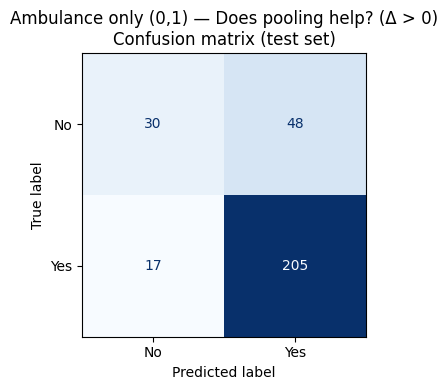

In [19]:
tree_amb_helps, X_test_amb_h, y_test_amb_h = run_tree(
    X, (comp["delta"] > 0).astype(int).values,
    "Ambulance only (0,1)", "Does pooling help? (\u0394 > 0)",
    class_names={0: "No", 1: "Yes"},
)

In [20]:
display_rules(tree_amb_helps, X_test_amb_h, y_test_amb_h,
              feature_cols, {0: "No", 1: "Yes"}, target_class=1,
              label="Ambulance only (0,1) — helps")


  Ambulance only (0,1) — helps — Rules predicting: Yes

  Rule 1:
      IF  bcas_rate ≤ 0.0125
      AND fraction_t1_bcas > 0.1326
      AND r1_r2_other_bde_min ≤ 92.8
      AND axp_r1_same_bde_min ≤ 63.6
    → Yes
    Test: 15 samples | precision=53% | recall=4% (covers 8/222 positives)

  Rule 2:
      IF  bcas_rate ≤ 0.0125
      AND fraction_t1_bcas > 0.1326
      AND r1_r2_other_bde_min > 92.8
      AND ccp_r1_inter_bn_min ≤ 37.5
    → Yes
    Test: 27 samples | precision=59% | recall=7% (covers 16/222 positives)

  Rule 3:
      IF  bcas_rate > 0.0125
      AND fraction_t1_bcas ≤ 0.397
      AND fraction_t1_bcas ≤ 0.2992
      AND ccp_r1_same_bn_min ≤ 9.0
    → Yes
    Test: 36 samples | precision=94% | recall=15% (covers 34/222 positives)

  Rule 4:
      IF  bcas_rate > 0.0125
      AND fraction_t1_bcas ≤ 0.397
      AND fraction_t1_bcas ≤ 0.2992
      AND ccp_r1_same_bn_min > 9.0
    → Yes
    Test: 94 samples | precision=95% | recall=40% (covers 89/222 positives)

  Rule 5:


  Ambulance only (0,1) — Does pooling help a lot? (Δ > 5%)
    No: 640
    Yes: 360
  Train acc: 0.820  Test acc: 0.723  (train=700, test=300)

              precision    recall  f1-score   support

          No       0.80      0.76      0.78       192
         Yes       0.61      0.66      0.63       108

    accuracy                           0.72       300
   macro avg       0.70      0.71      0.70       300
weighted avg       0.73      0.72      0.73       300

  Feature importances (>1%):
    bcas_rate                       0.498
    fraction_t1_bcas                0.245
    r1_r2_other_bde_min             0.117
    r2_r2_other_bde_min             0.060
    n_days                          0.047
    axp_r1_same_bde_min             0.032



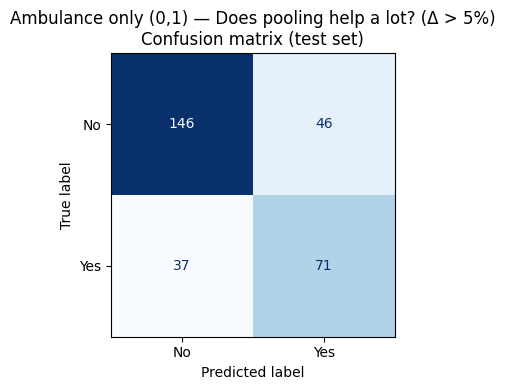

In [21]:
tree_amb_lot, X_test_amb_l, y_test_amb_l = run_tree(
    X, (comp["delta"] > THRESHOLD).astype(int).values,
    "Ambulance only (0,1)", f"Does pooling help a lot? (\u0394 > {THRESHOLD:.0%})",
    class_names={0: "No", 1: "Yes"},
)

In [22]:
display_rules(tree_amb_lot, X_test_amb_l, y_test_amb_l,
              feature_cols, {0: "No", 1: "Yes"}, target_class=1,
              label="Ambulance only (0,1) — helps a lot")


  Ambulance only (0,1) — helps a lot — Rules predicting: Yes

  Rule 1:
      IF  bcas_rate > 0.0125
      AND fraction_t1_bcas ≤ 0.2596
      AND n_days ≤ 4.5
      AND r2_r2_other_bde_min > 79.7
    → Yes
    Test: 86 samples | precision=60% | recall=48% (covers 52/108 positives)

  Rule 2:
      IF  bcas_rate > 0.0125
      AND fraction_t1_bcas ≤ 0.2596
      AND n_days > 4.5
      AND axp_r1_same_bde_min > 57.6
    → Yes
    Test: 13 samples | precision=46% | recall=6% (covers 6/108 positives)

  Rule 3:
      IF  bcas_rate > 0.0125
      AND fraction_t1_bcas > 0.2596
      AND r1_r2_other_bde_min ≤ 97.5
      AND bcas_rate ≤ 0.0275
    → Yes
    Test: 18 samples | precision=72% | recall=12% (covers 13/108 positives)



  Ambulance only (0,1) — Does pooling harm? (Δ < 0)
    No: 880
    Yes: 120
  Train acc: 0.939  Test acc: 0.910  (train=700, test=300)

              precision    recall  f1-score   support

          No       0.91      0.99      0.95       264
         Yes       0.85      0.31      0.45        36

    accuracy                           0.91       300
   macro avg       0.88      0.65      0.70       300
weighted avg       0.90      0.91      0.89       300

  Feature importances (>1%):
    bcas_rate                       0.377
    fraction_t1_bcas                0.352
    r1_r2_other_bde_min             0.252
    n_days                          0.015



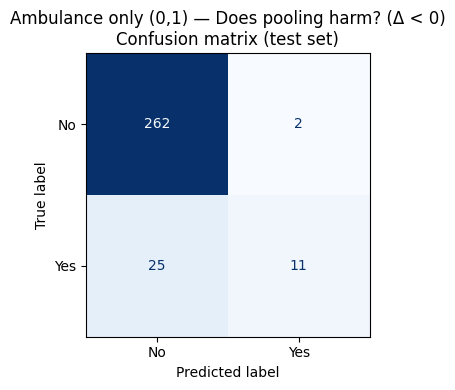

In [23]:
tree_amb_harms, X_test_amb_hr, y_test_amb_hr = run_tree(
    X, (comp["delta"] < 0).astype(int).values,
    "Ambulance only (0,1)", "Does pooling harm? (\u0394 < 0)",
    class_names={0: "No", 1: "Yes"},
)

In [24]:
display_rules(tree_amb_harms, X_test_amb_hr, y_test_amb_hr,
              feature_cols, {0: "No", 1: "Yes"}, target_class=1,
              label="Ambulance only (0,1) — harms")


  Ambulance only (0,1) — harms — Rules predicting: Yes

  Rule 1:
      IF  fraction_t1_bcas ≤ 0.4356
      AND fraction_t1_bcas > 0.3016
      AND bcas_rate > 0.0425
      AND r1_r2_other_bde_min > 102.3
    → Yes
    Test: 5 samples | precision=80% | recall=11% (covers 4/36 positives)

  Rule 2:
      IF  fraction_t1_bcas > 0.4356
      AND bcas_rate > 0.0275
      AND r1_r2_other_bde_min > 97.9
    → Yes
    Test: 8 samples | precision=88% | recall=19% (covers 7/36 positives)



  Ambulance only (0,1) — Does pooling harm a lot? (Δ < -5%)
    No: 973
    Yes: 27
  Train acc: 0.973  Test acc: 0.973  (train=700, test=300)

              precision    recall  f1-score   support

          No       0.97      1.00      0.99       292
         Yes       0.00      0.00      0.00         8

    accuracy                           0.97       300
   macro avg       0.49      0.50      0.49       300
weighted avg       0.95      0.97      0.96       300

  Feature importances (>1%):
    fraction_t1_bcas                0.663
    r1_r2_other_bde_min             0.317
    fraction_t2_bcas                0.011



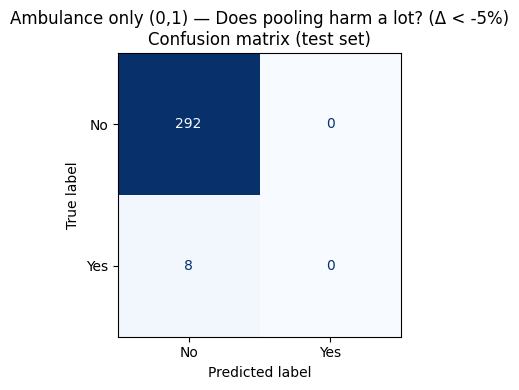

In [25]:
tree_amb_hlot, X_test_amb_hl, y_test_amb_hl = run_tree(
    X, (comp["delta"] < -THRESHOLD).astype(int).values,
    "Ambulance only (0,1)", f"Does pooling harm a lot? (\u0394 < -{THRESHOLD:.0%})",
    class_names={0: "No", 1: "Yes"},
)

In [26]:
display_rules(tree_amb_hlot, X_test_amb_hl, y_test_amb_hl,
              feature_cols, {0: "No", 1: "Yes"}, target_class=1,
              label="Ambulance only (0,1) — harms a lot")

  No paths lead to class Yes.



  Ambulance only (0,1) — 4-class
    Harms a lot: 27
    Harms a bit: 93
    Helps a bit: 520
    Helps a lot: 360
  Train acc: 0.693  Test acc: 0.663  (train=700, test=300)

              precision    recall  f1-score   support

 Harms a lot       0.30      0.38      0.33         8
 Harms a bit       0.32      0.32      0.32        28
 Helps a bit       0.85      0.60      0.70       156
 Helps a lot       0.62      0.86      0.72       108

    accuracy                           0.66       300
   macro avg       0.52      0.54      0.52       300
weighted avg       0.70      0.66      0.66       300

  Feature importances (>1%):
    bcas_rate                       0.588
    fraction_t1_bcas                0.250
    r1_r2_other_bde_min             0.126
    ccp_r1_inter_bn_min             0.030



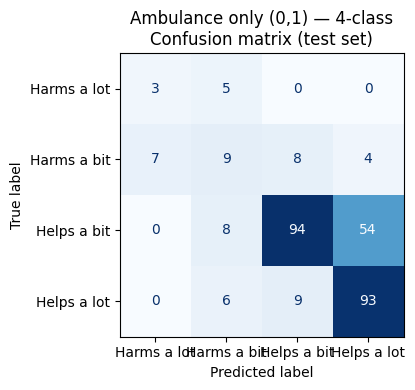

In [27]:
tree_amb_4c, X_test_amb_4, y_test_amb_4 = run_tree(
    cd["X"], cd["y4"],
    "Ambulance only (0,1)", "4-class",
    class_names=CLASS_NAMES_4,
)

In [28]:
for tc in range(4):
    display_rules(tree_amb_4c, X_test_amb_4, y_test_amb_4,
                  feature_cols, CLASS_NAMES_4, target_class=tc,
                  label="Ambulance only (0,1) — 4-class")


  Ambulance only (0,1) — 4-class — Rules predicting: Harms a lot

  Rule 1:
      IF  bcas_rate > 0.0125
      AND fraction_t1_bcas > 0.3822
      AND r1_r2_other_bde_min > 113.5
    → Harms a lot
    Test: 10 samples | precision=30% | recall=38% (covers 3/8 positives)


  Ambulance only (0,1) — 4-class — Rules predicting: Harms a bit

  Rule 1:
      IF  bcas_rate > 0.0125
      AND fraction_t1_bcas > 0.3822
      AND r1_r2_other_bde_min ≤ 113.5
      AND bcas_rate > 0.0275
    → Harms a bit
    Test: 28 samples | precision=32% | recall=32% (covers 9/28 positives)


  Ambulance only (0,1) — 4-class — Rules predicting: Helps a bit

  Rule 1:
      IF  bcas_rate ≤ 0.0125
      AND ccp_r1_same_bn_min ≤ 18.6
      AND fraction_t2_bcas ≤ 0.3832
    → Helps a bit
    Test: 54 samples | precision=98% | recall=34% (covers 53/156 positives)

  Rule 2:
      IF  bcas_rate ≤ 0.0125
      AND ccp_r1_same_bn_min ≤ 18.6
      AND fraction_t2_bcas > 0.3832
      AND axp_r1_other_bde_min ≤ 100.0
   

## Both (1,1)

In [29]:
cd = combo_data["Both (1,1)"]
X, comp = cd["X"], cd["comp"]

  Both (1,1) — Does pooling help? (Δ > 0)
    No: 314
    Yes: 686
  Train acc: 0.824  Test acc: 0.810  (train=700, test=300)

              precision    recall  f1-score   support

          No       0.78      0.55      0.65        94
         Yes       0.82      0.93      0.87       206

    accuracy                           0.81       300
   macro avg       0.80      0.74      0.76       300
weighted avg       0.81      0.81      0.80       300

  Feature importances (>1%):
    bcas_rate                       0.392
    fraction_t1_bcas                0.294
    r1_r2_other_bde_min             0.189
    n_days                          0.044
    ccp_r1_same_bn_min              0.032
    ccp_r1_inter_bn_min             0.032
    r1_r2_same_bde_min              0.018



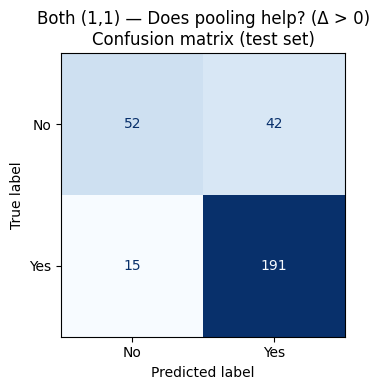

In [30]:
tree_both_helps, X_test_both_h, y_test_both_h = run_tree(
    X, (comp["delta"] > 0).astype(int).values,
    "Both (1,1)", "Does pooling help? (\u0394 > 0)",
    class_names={0: "No", 1: "Yes"},
)

In [31]:
display_rules(tree_both_helps, X_test_both_h, y_test_both_h,
              feature_cols, {0: "No", 1: "Yes"}, target_class=1,
              label="Both (1,1) — helps")


  Both (1,1) — helps — Rules predicting: Yes

  Rule 1:
      IF  fraction_t1_bcas ≤ 0.3869
      AND bcas_rate ≤ 0.0125
      AND n_days > 2.5
      AND ccp_r1_same_bn_min > 12.7
    → Yes
    Test: 21 samples | precision=57% | recall=6% (covers 12/206 positives)

  Rule 2:
      IF  fraction_t1_bcas ≤ 0.3869
      AND bcas_rate > 0.0125
      AND fraction_t1_bcas ≤ 0.2767
      AND fraction_t1_bcas ≤ 0.2103
    → Yes
    Test: 92 samples | precision=93% | recall=42% (covers 86/206 positives)

  Rule 3:
      IF  fraction_t1_bcas ≤ 0.3869
      AND bcas_rate > 0.0125
      AND fraction_t1_bcas ≤ 0.2767
      AND fraction_t1_bcas > 0.2103
    → Yes
    Test: 32 samples | precision=88% | recall=14% (covers 28/206 positives)

  Rule 4:
      IF  fraction_t1_bcas ≤ 0.3869
      AND bcas_rate > 0.0125
      AND fraction_t1_bcas > 0.2767
      AND r1_r2_other_bde_min ≤ 88.4
    → Yes
    Test: 15 samples | precision=80% | recall=6% (covers 12/206 positives)

  Rule 5:
      IF  fraction_t1

  Both (1,1) — Does pooling help a lot? (Δ > 5%)
    No: 740
    Yes: 260
  Train acc: 0.797  Test acc: 0.747  (train=700, test=300)

              precision    recall  f1-score   support

          No       0.83      0.82      0.83       222
         Yes       0.51      0.54      0.53        78

    accuracy                           0.75       300
   macro avg       0.67      0.68      0.68       300
weighted avg       0.75      0.75      0.75       300

  Feature importances (>1%):
    bcas_rate                       0.448
    fraction_t1_bcas                0.294
    r1_r2_other_bde_min             0.161
    r1_r1_inter_bn_min              0.050
    n_days                          0.046



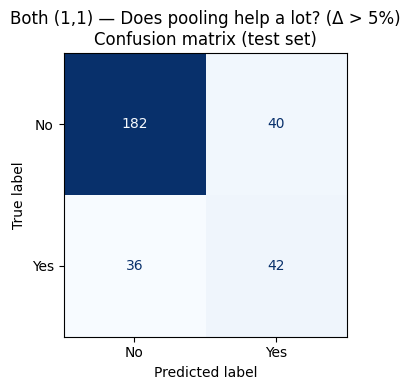

In [32]:
tree_both_lot, X_test_both_l, y_test_both_l = run_tree(
    X, (comp["delta"] > THRESHOLD).astype(int).values,
    "Both (1,1)", f"Does pooling help a lot? (\u0394 > {THRESHOLD:.0%})",
    class_names={0: "No", 1: "Yes"},
)

In [33]:
display_rules(tree_both_lot, X_test_both_l, y_test_both_l,
              feature_cols, {0: "No", 1: "Yes"}, target_class=1,
              label="Both (1,1) — helps a lot")


  Both (1,1) — helps a lot — Rules predicting: Yes

  Rule 1:
      IF  bcas_rate > 0.0125
      AND fraction_t1_bcas ≤ 0.2747
      AND r1_r2_other_bde_min ≤ 108.7
      AND n_days ≤ 4.5
    → Yes
    Test: 73 samples | precision=55% | recall=51% (covers 40/78 positives)

  Rule 2:
      IF  bcas_rate > 0.0125
      AND fraction_t1_bcas ≤ 0.2747
      AND r1_r2_other_bde_min > 108.7
      AND r1_r1_inter_bn_min ≤ 26.9
    → Yes
    Test: 9 samples | precision=22% | recall=3% (covers 2/78 positives)



  Both (1,1) — Does pooling harm? (Δ < 0)
    No: 827
    Yes: 173
  Train acc: 0.904  Test acc: 0.910  (train=700, test=300)

              precision    recall  f1-score   support

          No       0.93      0.97      0.95       248
         Yes       0.80      0.63      0.71        52

    accuracy                           0.91       300
   macro avg       0.87      0.80      0.83       300
weighted avg       0.91      0.91      0.91       300

  Feature importances (>1%):
    fraction_t1_bcas                0.392
    bcas_rate                       0.335
    r1_r2_other_bde_min             0.257
    ccp_r1_same_bn_min              0.016



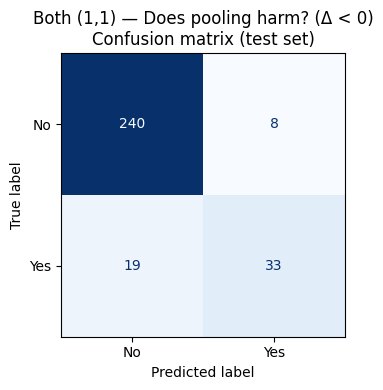

In [34]:
tree_both_harms, X_test_both_hr, y_test_both_hr = run_tree(
    X, (comp["delta"] < 0).astype(int).values,
    "Both (1,1)", "Does pooling harm? (\u0394 < 0)",
    class_names={0: "No", 1: "Yes"},
)

In [35]:
display_rules(tree_both_harms, X_test_both_hr, y_test_both_hr,
              feature_cols, {0: "No", 1: "Yes"}, target_class=1,
              label="Both (1,1) — harms")


  Both (1,1) — harms — Rules predicting: Yes

  Rule 1:
      IF  fraction_t1_bcas ≤ 0.3869
      AND fraction_t1_bcas > 0.2384
      AND r1_r2_other_bde_min > 97.6
      AND bcas_rate > 0.0275
    → Yes
    Test: 18 samples | precision=72% | recall=25% (covers 13/52 positives)

  Rule 2:
      IF  fraction_t1_bcas > 0.3869
      AND bcas_rate > 0.0275
      AND r1_r2_other_bde_min > 87.7
      AND r1_r2_other_bde_min ≤ 101.3
    → Yes
    Test: 5 samples | precision=60% | recall=6% (covers 3/52 positives)

  Rule 3:
      IF  fraction_t1_bcas > 0.3869
      AND bcas_rate > 0.0275
      AND r1_r2_other_bde_min > 87.7
      AND r1_r2_other_bde_min > 101.3
    → Yes
    Test: 18 samples | precision=94% | recall=33% (covers 17/52 positives)



  Both (1,1) — Does pooling harm a lot? (Δ < -5%)
    No: 954
    Yes: 46
  Train acc: 0.970  Test acc: 0.970  (train=700, test=300)

              precision    recall  f1-score   support

          No       0.98      0.99      0.98       286
         Yes       0.78      0.50      0.61        14

    accuracy                           0.97       300
   macro avg       0.88      0.75      0.80       300
weighted avg       0.97      0.97      0.97       300

  Feature importances (>1%):
    r1_r2_other_bde_min             0.440
    fraction_t1_bcas                0.282
    bcas_rate                       0.253
    axp_r1_other_bde_min            0.013



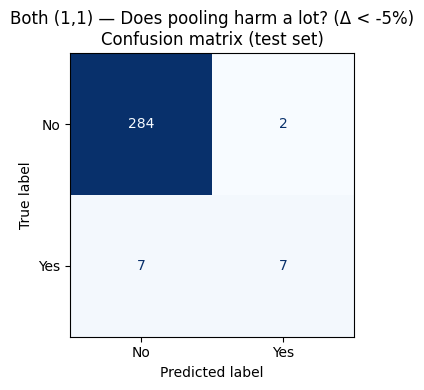

In [36]:
tree_both_hlot, X_test_both_hl, y_test_both_hl = run_tree(
    X, (comp["delta"] < -THRESHOLD).astype(int).values,
    "Both (1,1)", f"Does pooling harm a lot? (\u0394 < -{THRESHOLD:.0%})",
    class_names={0: "No", 1: "Yes"},
)

In [37]:
display_rules(tree_both_hlot, X_test_both_hl, y_test_both_hl,
              feature_cols, {0: "No", 1: "Yes"}, target_class=1,
              label="Both (1,1) — harms a lot")


  Both (1,1) — harms a lot — Rules predicting: Yes

  Rule 1:
      IF  fraction_t1_bcas > 0.4356
      AND bcas_rate > 0.0275
      AND r1_r2_other_bde_min > 104.8
    → Yes
    Test: 9 samples | precision=78% | recall=50% (covers 7/14 positives)



  Both (1,1) — 4-class
    Harms a lot: 46
    Harms a bit: 127
    Helps a bit: 567
    Helps a lot: 260
  Train acc: 0.673  Test acc: 0.593  (train=700, test=300)

              precision    recall  f1-score   support

 Harms a lot       0.39      0.50      0.44        14
 Harms a bit       0.00      0.00      0.00        38
 Helps a bit       0.64      0.81      0.71       170
 Helps a lot       0.50      0.44      0.47        78

    accuracy                           0.59       300
   macro avg       0.38      0.44      0.40       300
weighted avg       0.51      0.59      0.55       300

  Feature importances (>1%):
    bcas_rate                       0.538
    r1_r2_other_bde_min             0.211
    fraction_t1_bcas                0.210
    ccp_r1_same_bn_min              0.041



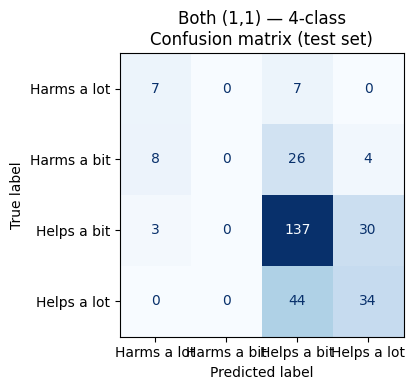

In [38]:
tree_both_4c, X_test_both_4, y_test_both_4 = run_tree(
    cd["X"], cd["y4"],
    "Both (1,1)", "4-class",
    class_names=CLASS_NAMES_4,
)

In [39]:
for tc in range(4):
    display_rules(tree_both_4c, X_test_both_4, y_test_both_4,
                  feature_cols, CLASS_NAMES_4, target_class=tc,
                  label="Both (1,1) — 4-class")


  Both (1,1) — 4-class — Rules predicting: Harms a lot

  Rule 1:
      IF  bcas_rate > 0.0125
      AND fraction_t1_bcas > 0.2967
      AND bcas_rate > 0.0275
      AND r1_r2_other_bde_min > 106.1
    → Harms a lot
    Test: 18 samples | precision=39% | recall=50% (covers 7/14 positives)

  No paths lead to class Harms a bit.


  Both (1,1) — 4-class — Rules predicting: Helps a bit

  Rule 1:
      IF  bcas_rate ≤ 0.0125
      AND ccp_r1_same_bn_min ≤ 18.7
      AND ccp_r1_same_bn_min ≤ 6.9
    → Helps a bit
    Test: 13 samples | precision=100% | recall=8% (covers 13/170 positives)

  Rule 2:
      IF  bcas_rate ≤ 0.0125
      AND ccp_r1_same_bn_min ≤ 18.7
      AND ccp_r1_same_bn_min > 6.9
      AND r1_r2_same_bde_min ≤ 71.6
    → Helps a bit
    Test: 45 samples | precision=100% | recall=26% (covers 45/170 positives)

  Rule 3:
      IF  bcas_rate ≤ 0.0125
      AND ccp_r1_same_bn_min ≤ 18.7
      AND ccp_r1_same_bn_min > 6.9
      AND r1_r2_same_bde_min > 71.6
    → Helps a bit
 

## Summary — Feature Importance Across All Trees

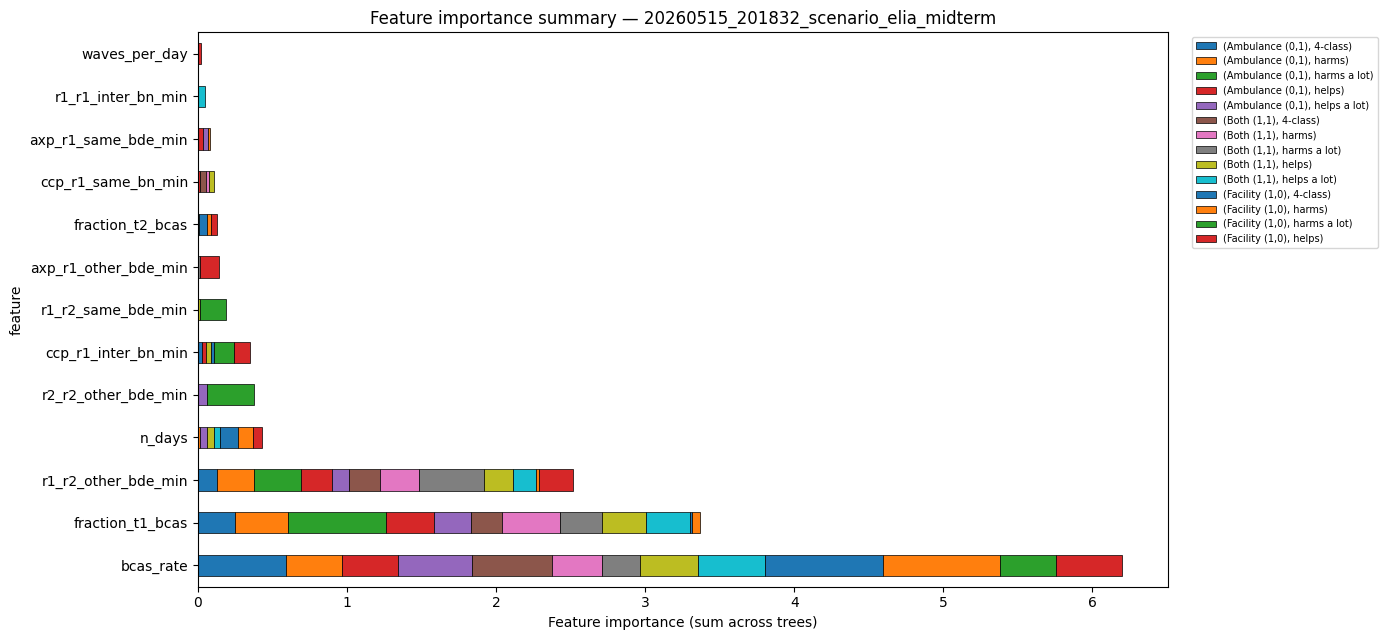

combo                Ambulance (0,1)                                        \
question                     4-class  harms harms a lot  helps helps a lot   
feature                                                                      
bcas_rate                      0.588  0.377       0.000  0.375       0.498   
fraction_t1_bcas               0.250  0.352       0.663  0.321       0.245   
r1_r2_other_bde_min            0.126  0.252       0.317  0.202       0.117   
n_days                         0.000  0.015       0.000  0.000       0.047   
r2_r2_other_bde_min            0.000  0.000       0.000  0.000       0.060   
ccp_r1_inter_bn_min            0.030  0.000       0.000  0.028       0.000   
r1_r2_same_bde_min             0.000  0.000       0.000  0.000       0.000   
axp_r1_other_bde_min           0.000  0.000       0.000  0.000       0.000   
fraction_t2_bcas               0.000  0.000       0.011  0.000       0.000   
ccp_r1_same_bn_min             0.000  0.000       0.000  0.017       0.000   
axp_r1_same_bde_min            0.000  0.000       0.000  0.036       0.032   
r1_r1_inter_bn_min             0.000  0.000       0.000  0.000       0.000   
waves_per_day                  0.000  0.000       0.000  0.022       0.000   

combo                Both (1,1)                                        \
question                4-class  harms harms a lot  helps helps a lot   
feature                                                                 
bcas_rate                 0.538  0.335       0.253  0.392       0.448   
fraction_t1_bcas          0.210  0.392       0.282  0.294       0.294   
r1_r2_other_bde_min       0.211  0.257       0.440  0.189       0.161   
n_days                    0.000  0.000       0.000  0.044       0.046   
r2_r2_other_bde_min       0.000  0.000       0.000  0.000       0.000   
ccp_r1_inter_bn_min       0.000  0.000       0.000  0.032       0.000   
r1_r2_same_bde_min        0.000  0.000       0.000  0.018       0.000   
axp_r1_other_bde_min      0.000  0.000       0.013  0.000       0.000   
fraction_t2_bcas          0.000  0.000       0.000  0.000       0.000   
ccp_r1_same_bn_min        0.041  0.016       0.000  0.032       0.000   
axp_r1_same_bde_min       0.000  0.000       0.000  0.000       0.000   
r1_r1_inter_bn_min        0.000  0.000       0.000  0.000       0.050   
waves_per_day             0.000  0.000       0.000  0.000       0.000   

combo                Facility (1,0)                            
question                    4-class  harms harms a lot  helps  
feature                                                        
bcas_rate                     0.790  0.784       0.377  0.442  
fraction_t1_bcas              0.011  0.054       0.000  0.000  
r1_r2_other_bde_min           0.000  0.019       0.000  0.226  
n_days                        0.115  0.105       0.000  0.058  
r2_r2_other_bde_min           0.000  0.000       0.317  0.000  
ccp_r1_inter_bn_min           0.022  0.000       0.129  0.109  
r1_r2_same_bde_min            0.000  0.000       0.172  0.000  
axp_r1_other_bde_min          0.000  0.000       0.000  0.127  
fraction_t2_bcas              0.052  0.024       0.000  0.039  
ccp_r1_same_bn_min            0.000  0.000       0.000  0.000  
axp_r1_same_bde_min           0.000  0.015       0.000  0.000  
r1_r1_inter_bn_min            0.000  0.000       0.000  0.000  
waves_per_day                 0.000  0.000       0.000  0.000

In [40]:
all_trees = {
    ("Facility (1,0)", "helps"): tree_fac_helps,
    ("Facility (1,0)", "helps a lot"): tree_fac_lot,
    ("Facility (1,0)", "harms"): tree_fac_harms,
    ("Facility (1,0)", "harms a lot"): tree_fac_hlot,
    ("Facility (1,0)", "4-class"): tree_fac_4c,
    ("Ambulance (0,1)", "helps"): tree_amb_helps,
    ("Ambulance (0,1)", "helps a lot"): tree_amb_lot,
    ("Ambulance (0,1)", "harms"): tree_amb_harms,
    ("Ambulance (0,1)", "harms a lot"): tree_amb_hlot,
    ("Ambulance (0,1)", "4-class"): tree_amb_4c,
    ("Both (1,1)", "helps"): tree_both_helps,
    ("Both (1,1)", "helps a lot"): tree_both_lot,
    ("Both (1,1)", "harms"): tree_both_harms,
    ("Both (1,1)", "harms a lot"): tree_both_hlot,
    ("Both (1,1)", "4-class"): tree_both_4c,
}

rows = []
for (combo, question), tree in all_trees.items():
    if tree is None:
        continue
    for feat, imp in zip(feature_cols, tree.feature_importances_):
        if imp > 0.01:
            rows.append({"combo": combo, "question": question,
                         "feature": feat, "importance": imp})

if rows:
    imp_df = pd.DataFrame(rows)
    pivot = imp_df.pivot_table(index="feature", columns=["combo", "question"],
                               values="importance", fill_value=0)
    pivot["total"] = pivot.sum(axis=1)
    pivot = pivot.sort_values("total", ascending=False).drop(columns="total")

    fig, ax = plt.subplots(figsize=(14, max(4, len(pivot) * 0.5)))
    pivot.plot.barh(ax=ax, stacked=True, edgecolor="black", linewidth=0.5)
    ax.set_xlabel("Feature importance (sum across trees)")
    ax.set_title(f"Feature importance summary — {FOLDER_NAME}")
    ax.legend(bbox_to_anchor=(1.02, 1), loc="upper left", fontsize=7)
    plt.tight_layout()
    plt.show()

    display(pivot.round(3))
else:
    print("No trees produced meaningful splits.")